# Logistic regression: does fire and weather information improve next-day prediction of high-PM2.5 hours in Singapore?

Companion to `linear_regression.ipynb`. That notebook predicts the PM2.5 level; this one predicts the **event** the project question is about: will the island-mean PM2.5 at t + 24 h be high?

Same data (`data/processed/model_table.csv`), same split and same rules:

- time-based split by forecast time: train ≤ 14 Oct (targets ≤ 15 Oct), 15 Oct embargoed, final test 16–30 Oct 2023, used once at the end;
- threshold, sectors, cut-off and model choice use training data only (rolling-origin validation over 1–14 Oct);
- every model is compared with persistence ("high now → high tomorrow") and climatology (the training base rate).

# 1. Packages and data

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
SGT = "Asia/Singapore"
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

table = pd.read_csv("data/processed/model_table.csv", index_col="timestamp")
table.index = pd.to_datetime(table.index, utc=True).tz_convert(SGT)
table["target_time"] = pd.to_datetime(table["target_time"], utc=True).dt.tz_convert(SGT)

# split dates, declared up front (identical to linear_regression.ipynb)
TRAIN_LAST_TARGET = pd.Timestamp("2023-10-15 23:00", tz=SGT)
TEST_START = pd.Timestamp("2023-10-16 00:00", tz=SGT)
TEST_LAST_ORIGIN = pd.Timestamp("2023-10-30 23:00", tz=SGT)

WEATHER_OK = table["temp"].notna().mean() > 0.9
print(table.shape, "| weather coverage:", f"{table['temp'].notna().mean():.0%}", "| weather models used:", WEATHER_OK)

(1128, 31) | weather coverage: 98% | weather models used: True


## Defining a "high-PM2.5" hour

The island mean never reaches NEA Band II (≥ 56 µg/m³; maximum 54.4), so that threshold would give no events. We use **25 µg/m³**, the WHO 2021 interim target 4 for PM2.5. It is applied here to hourly values rather than 24-hour means, so it marks "elevated" rather than a regulatory exceedance. The threshold is fixed before looking at the test period. As the check below shows, it is also the 75th percentile of the training targets, so about one training hour in four is an event.

In [2]:
THRESHOLD = 25.0   # µg/m³
table["high"] = (table["y"] >= THRESHOLD).astype(float).where(table["y"].notna())

train_all = table[table["target_time"] <= TRAIN_LAST_TARGET]
print(f"training targets: {train_all['high'].notna().sum()} hours, "
      f"{train_all['high'].mean():.1%} high, 75th percentile of y = {train_all['y'].quantile(0.75):.1f} µg/m³")

training targets: 666 hours, 25.1% high, 75th percentile of y = 24.9 µg/m³


# 2. Explore the training period

Sectors are chosen exactly as in the linear notebook: those with at least 5% of the training-period fire radiative power.

In [3]:
sectors = ["N", "E", "S", "W"]
frp_total = pd.Series({s: np.expm1(train_all[f"frp_{s}_24h"]).sum() for s in sectors})
SECTORS_USED = list(frp_total.index[frp_total / frp_total.sum() >= 0.05])
print("sectors used in the models:", SECTORS_USED)

sectors used in the models: ['E', 'S']


## How the event rate depends on each predictor

For each candidate predictor we split the training hours into deciles and plot the share of high hours (left axis) and its empirical log-odds (right). A logistic model with a linear term assumes the log-odds line is roughly straight.

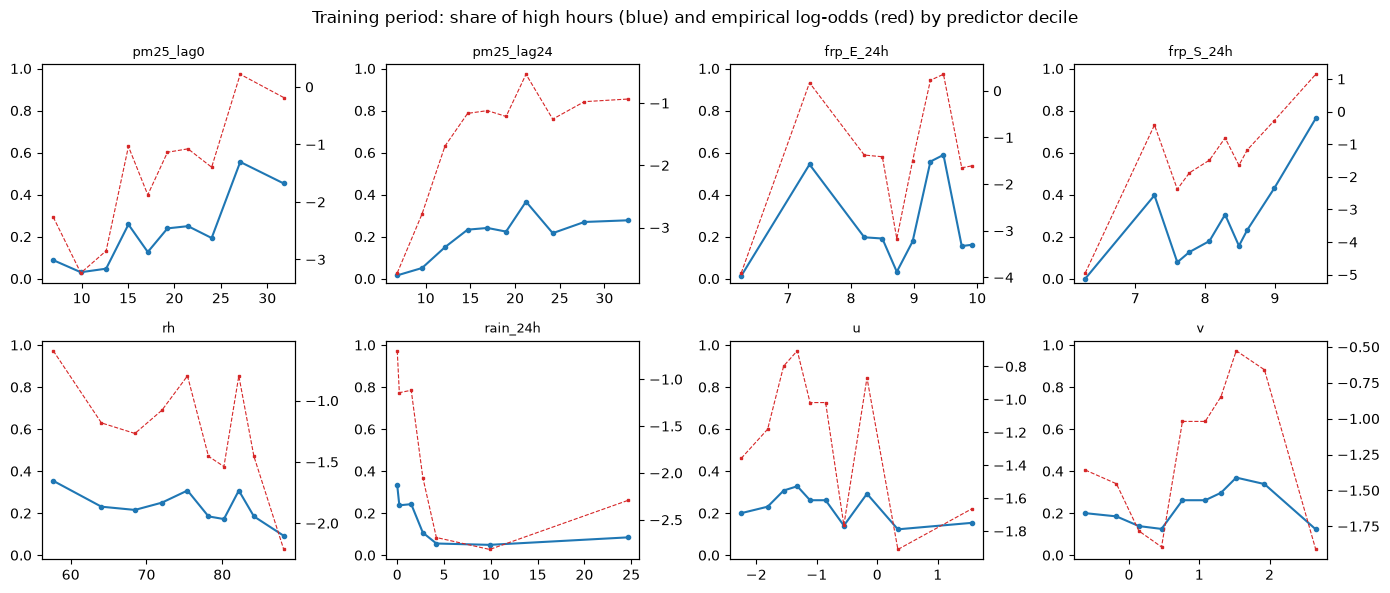

In [4]:
explore = ["pm25_lag0", "pm25_lag24"] + [f"frp_{s}_24h" for s in SECTORS_USED]
if WEATHER_OK:
    explore += ["rh", "rain_24h", "u", "v"]

ncol = 4
fig, axes = plt.subplots(int(np.ceil(len(explore) / ncol)), ncol, figsize=(14, 3 * int(np.ceil(len(explore) / ncol))))
for ax, v in zip(axes.flat, explore):
    d = train_all[[v, "high"]].dropna()
    bins = pd.qcut(d[v], 10, duplicates="drop")
    g = d.groupby(bins, observed=True).agg(x=(v, "mean"), rate=("high", "mean"), n=("high", "size"))
    rate = (g["rate"] * g["n"] + 0.5) / (g["n"] + 1)          # +0.5 / +1 keeps empty or full bins finite
    ax.plot(g["x"], g["rate"], "o-", ms=3); ax.set_ylim(-0.02, 1.02); ax.set_title(v, fontsize=9)
    ax2 = ax.twinx(); ax2.plot(g["x"], np.log(rate / (1 - rate)), "s--", ms=2, c="tab:red", lw=0.8)
for ax in list(axes.flat)[len(explore):]:
    ax.axis("off")
fig.suptitle("Training period: share of high hours (blue) and empirical log-odds (red) by predictor decile")
plt.tight_layout(); plt.show()

In [5]:
# the same information from the other side: predictor means by class
train_all.groupby("high")[explore].mean().T.round(2).rename(columns={0.0: "mean | not high", 1.0: "mean | high"})

high,mean | not high,mean | high
pm25_lag0,17.07,23.13
pm25_lag24,17.61,21.30
frp_E_24h,8.52,8.85
frp_S_24h,7.88,8.61
rh,75.62,73.13
rain_24h,5.00,1.50
u,-0.72,-0.94
v,0.87,1.01


# 3. Training and evaluation sets

In [6]:
season = "hour_sin + hour_cos + is_weekend"
f_base = "pm25_lag0 + pm25_lag24 + " + season
f_fire_terms = " + ".join(f"frp_{s}_24h" for s in SECTORS_USED)
f_transport_terms = " + ".join(f"transport_{s}" for s in SECTORS_USED)

formulas = {"Season only": "high ~ " + season, "Baseline (persistence + season)": "high ~ " + f_base}
if WEATHER_OK:
    f_weather = f_base + " + temp + rh + rain_24h + u + v"
    formulas["+ Weather"] = "high ~ " + f_weather
    formulas["+ Weather + Fire"] = "high ~ " + f_weather + " + " + f_fire_terms
    formulas["+ Weather + Fire + Transport"] = "high ~ " + f_weather + " + " + f_fire_terms + " + " + f_transport_terms
else:
    formulas["+ Fire"] = "high ~ " + f_base + " + " + f_fire_terms
FULL = list(formulas)[-1]

# every model is fitted on the same rows, so likelihood-ratio tests between nested models are valid
used_cols = sorted({v for f in formulas.values() for v in f.split("~")[1].replace(" ", "").split("+")} | {"y", "high"})
complete = table.dropna(subset=used_cols)

train = complete[complete["target_time"] <= TRAIN_LAST_TARGET]
test = complete[(complete.index >= TEST_START) & (complete.index <= TEST_LAST_ORIGIN)]
assert train["target_time"].max() < test.index.min(), "a training target overlaps the test period"
print(f"training rows: {len(train)} ({int(train['high'].sum())} high)   test rows: {len(test)}")
for name, f in formulas.items():
    print(f"{name:32s} {f}")

training rows: 587 (117 high)   test rows: 334
Season only                      high ~ hour_sin + hour_cos + is_weekend
Baseline (persistence + season)  high ~ pm25_lag0 + pm25_lag24 + hour_sin + hour_cos + is_weekend
+ Weather                        high ~ pm25_lag0 + pm25_lag24 + hour_sin + hour_cos + is_weekend + temp + rh + rain_24h + u + v
+ Weather + Fire                 high ~ pm25_lag0 + pm25_lag24 + hour_sin + hour_cos + is_weekend + temp + rh + rain_24h + u + v + frp_E_24h + frp_S_24h
+ Weather + Fire + Transport     high ~ pm25_lag0 + pm25_lag24 + hour_sin + hour_cos + is_weekend + temp + rh + rain_24h + u + v + frp_E_24h + frp_S_24h + transport_E + transport_S


# 4. Simple logistic regression

## Model 1: is tomorrow high, given today's PM2.5?

$\log\frac{p}{1-p} = \beta_0 + \beta_1 \cdot \text{pm25\_lag0}$. Here $e^{\beta_1}$ is the odds ratio for a 1 µg/m³ increase in today's PM2.5.

In [7]:
logit_lag0 = smf.logit("high ~ pm25_lag0", data=train).fit(disp=0)
print(logit_lag0.summary())

                           Logit Regression Results                           
Dep. Variable:                   high   No. Observations:                  587
Model:                          Logit   Df Residuals:                      585
Method:                           MLE   Df Model:                            1
Date:                Sun, 08 Nov 2026   Pseudo R-squ.:                 0.06514
Time:                        21:02:29   Log-Likelihood:                -274.08
converged:                       True   LL-Null:                       -293.18
Covariance Type:            nonrobust   LLR p-value:                 6.405e-10
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -3.1439      0.333     -9.441      0.000      -3.797      -2.491
pm25_lag0      0.0909      0.015      5.926      0.000       0.061       0.121


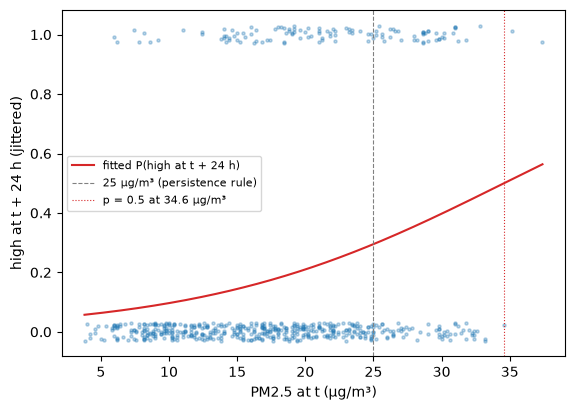

In [8]:
b0, b1 = logit_lag0.params
xs = np.linspace(train["pm25_lag0"].min(), train["pm25_lag0"].max(), 200)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(train["pm25_lag0"], train["high"] + np.random.default_rng(0).uniform(-0.03, 0.03, len(train)), s=5, alpha=0.3)
ax.plot(xs, 1 / (1 + np.exp(-(b0 + b1 * xs))), c="tab:red", label="fitted P(high at t + 24 h)")
ax.axvline(THRESHOLD, ls="--", c="grey", lw=0.8, label=f"{THRESHOLD:g} µg/m³ (persistence rule)")
ax.axvline(-b0 / b1, ls=":", c="tab:red", lw=0.8, label=f"p = 0.5 at {-b0 / b1:.1f} µg/m³")
ax.set(xlabel="PM2.5 at t (µg/m³)", ylabel="high at t + 24 h (jittered)"); ax.legend(fontsize=8); plt.show()

## Compute the log-likelihood directly

As a check on statsmodels: $\ell = \sum_i [y_i \log p_i + (1-y_i)\log(1-p_i)]$, McFadden's pseudo-$R^2 = 1 - \ell/\ell_0$ where $\ell_0$ is the intercept-only model, and $\text{AIC} = -2\ell + 2k$.

In [9]:
p_hat = logit_lag0.predict(train)
ll = np.sum(train["high"] * np.log(p_hat) + (1 - train["high"]) * np.log(1 - p_hat))
pbar = train["high"].mean()
ll0 = len(train) * (pbar * np.log(pbar) + (1 - pbar) * np.log(1 - pbar))
pd.DataFrame({
    "manual": [ll, ll0, 1 - ll / ll0, -2 * ll + 2 * len(logit_lag0.params)],
    "statsmodels": [logit_lag0.llf, logit_lag0.llnull, logit_lag0.prsquared, logit_lag0.aic]},
    index=["log-likelihood", "null log-likelihood", "McFadden pseudo-R²", "AIC"]).round(6)

,manual,statsmodels
log-likelihood,-274.083917,-274.083917
null log-likelihood,-293.180852,-293.180852
McFadden pseudo-R²,0.065137,0.065137
AIC,552.167835,552.167835


## One-predictor models

In [10]:
rows = []
for v in explore:
    m = smf.logit(f"high ~ {v}", data=train).fit(disp=0)
    rows.append({"predictor": v, "coef": m.params[v], "odds_ratio": np.exp(m.params[v]),
                 "p_value": m.pvalues[v], "pseudo_R2": m.prsquared, "AIC": m.aic})
pd.DataFrame(rows).set_index("predictor").sort_values("AIC").round(4)

,coef,odds_ratio,p_value,pseudo_R2,AIC
predictor,,,,,
frp_S_24h,1.4379,4.2118,0.0000,0.1658,493.1239
frp_E_24h,1.0876,2.9672,0.0000,0.1079,527.0744
pm25_lag0,0.0909,1.0952,0.0000,0.0651,552.1678
rain_24h,-0.1069,0.8986,0.0002,0.0439,564.6218
pm25_lag24,0.0576,1.0593,0.0000,0.0312,572.0437
v,0.4025,1.4955,0.0002,0.0235,576.5734
rh,-0.0342,0.9664,0.0024,0.0156,581.2027
u,-0.1328,0.8756,0.1686,0.0033,588.4110


## Odds ratios with confidence intervals (Wald, 95%)

In [11]:
np.exp(pd.concat({"coef": logit_lag0.params, "2.5%": logit_lag0.conf_int()[0], "97.5%": logit_lag0.conf_int()[1]}, axis=1)).round(4)

,coef,2.5%,97.5%
Intercept,0.0431,0.0224,0.0828
pm25_lag0,1.0952,1.0627,1.1286


# 5. Multiple logistic regression

In [12]:
with warnings.catch_warnings():
    warnings.simplefilter("error", sm.tools.sm_exceptions.PerfectSeparationWarning)  # fail loudly on separation
    models = {name: smf.logit(f, data=train).fit(disp=0, maxiter=200) for name, f in formulas.items()}
assert all(m.mle_retvals["converged"] for m in models.values()), "a model did not converge"

for name, m in models.items():
    print(f"\n=== {name} ===")
    print(m.summary().tables[1])


=== Season only ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.3182      0.120    -10.956      0.000      -1.554      -1.082
hour_sin      -0.2893      0.147     -1.962      0.050      -0.578      -0.000
hour_cos      -0.0664      0.147     -0.451      0.652      -0.355       0.222
is_weekend    -0.3059      0.240     -1.276      0.202      -0.776       0.164

=== Baseline (persistence + season) ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -3.2889      0.371     -8.876      0.000      -4.015      -2.563
pm25_lag0      0.0793      0.017      4.642      0.000       0.046       0.113
pm25_lag24     0.0248      0.015      1.622      0.105      -0.005       0.055
hour_sin      -0.2585      0.153     -1.689      0.091      -0.558   

## Nested models: likelihood-ratio tests

Each row compares a model with the one above it: $LR = 2(\ell_{\text{big}} - \ell_{\text{small}}) \sim \chi^2_{\Delta k}$ under the null that the extra terms are zero. This is the logistic analogue of the ANOVA F-test in the linear notebook. It assumes independent hours, which is not true (see section 6), so the p-values are optimistic.

In [13]:
names = list(models)
lr_rows = []
for small, big in zip(names[:-1], names[1:]):
    ms, mb = models[small], models[big]
    lr = 2 * (mb.llf - ms.llf); df = mb.df_model - ms.df_model
    lr_rows.append({"model": big, "added_terms": int(df), "LR": lr, "p_value": stats.chi2.sf(lr, df)})
training_comparison = pd.DataFrame({
    "parameters": [len(m.params) for m in models.values()],
    "log_likelihood": [m.llf for m in models.values()],
    "McFadden_R2": [m.prsquared for m in models.values()],
    "AIC": [m.aic for m in models.values()], "BIC": [m.bic for m in models.values()],
}, index=names)
training_comparison.join(pd.DataFrame(lr_rows).set_index("model")).round(4)

,parameters,log_likelihood,McFadden_R2,AIC,BIC,added_terms,LR,p_value
Season only,4,-290.3213,0.0098,588.6425,606.1426,NaN,NaN,NaN
Baseline (persistence + season),6,-269.7952,0.0798,551.5904,577.8405,2.0,41.0521,0.0000
+ Weather,11,-260.6582,0.1109,543.3165,591.4417,5.0,18.2739,0.0026
+ Weather + Fire,13,-213.0547,0.2733,452.1095,508.9848,2.0,95.2070,0.0000
+ Weather + Fire + Transport,15,-212.2431,0.2761,454.4861,520.1115,2.0,1.6233,0.4441


## Odds ratios of the full model, with ordinary and autocorrelation-robust (HAC) standard errors

In [14]:
model_full = models[FULL]
model_full_hac = smf.logit(formulas[FULL], data=train).fit(disp=0, maxiter=200, cov_type="HAC", cov_kwds={"maxlags": 24})
pd.DataFrame({
    "coef": model_full.params, "odds_ratio": np.exp(model_full.params),
    "se_ML": model_full.bse, "p_ML": model_full.pvalues,
    "se_HAC": model_full_hac.bse, "p_HAC": model_full_hac.pvalues,
}).round(4)

,coef,odds_ratio,se_ML,p_ML,se_HAC,p_HAC
Intercept,-67.2247,0.0000,14.2929,0.0000,22.3982,0.0027
pm25_lag0,-0.0066,0.9934,0.0248,0.7895,0.0403,0.8698
pm25_lag24,0.0849,1.0886,0.0203,0.0000,0.0264,0.0013
hour_sin,-1.2894,0.2754,0.3471,0.0002,0.6866,0.0604
hour_cos,-0.4269,0.6525,0.2681,0.1113,0.4815,0.3752
is_weekend,-0.6722,0.5106,0.3280,0.0404,0.5879,0.2528
temp,0.8903,2.4359,0.3005,0.0030,0.5145,0.0835
rh,0.2336,1.2631,0.0597,0.0001,0.0902,0.0096
rain_24h,-0.0345,0.9661,0.0506,0.4953,0.1378,0.8023
u,0.0160,1.0161,0.3819,0.9666,0.5076,0.9749


In [15]:
extra_terms = [t.strip() for t in (f_fire_terms + (" + " + f_transport_terms if WEATHER_OK else "")).split("+")]
wald = model_full_hac.wald_test(", ".join(f"{t} = 0" for t in extra_terms), scalar=True)
print("Robust (HAC) joint Wald test that all fire terms are zero:", extra_terms)
print(f"  chi2 = {float(np.squeeze(wald.statistic)):.3f}, df = {len(extra_terms)}, p = {float(wald.pvalue):.4f}")

Robust (HAC) joint Wald test that all fire terms are zero: ['frp_E_24h', 'frp_S_24h', 'transport_E', 'transport_S']
  chi2 = 33.288, df = 4, p = 0.0000


# 6. Diagnostics

Logistic regression has no normal-residual or constant-variance assumption, so the linear-model plots do not apply. We check instead:

1. **Linearity in the log-odds**: binned residuals against each continuous predictor should scatter around zero.
2. **Calibration**: within bins of predicted probability, the observed share of high hours should match the prediction (plus a Hosmer–Lemeshow test).
3. **Influential hours**: Cook's distance and leverage from the equivalent binomial GLM.
4. **Independence**: autocorrelation of the Pearson residuals over time.

Separation (a predictor splitting the classes perfectly) was already ruled out when the models were fitted: separation would have raised an error and convergence is asserted.

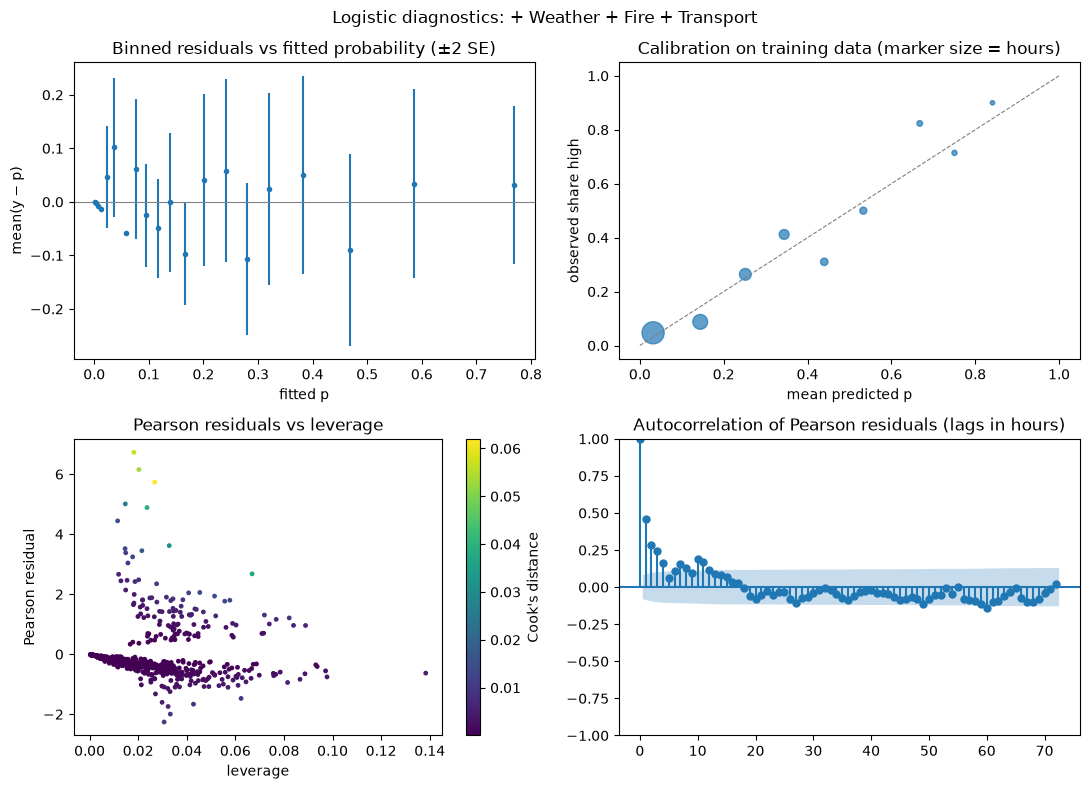

In [16]:
glm_full = smf.glm(formulas[FULL], data=train, family=sm.families.Binomial()).fit()
assert np.allclose(glm_full.params, model_full.params, atol=1e-5), "GLM and Logit fits disagree"
p_fit = glm_full.fittedvalues
resid_pearson = glm_full.resid_pearson
infl = glm_full.get_influence()
cooks, lev = infl.cooks_distance[0], infl.hat_matrix_diag

def binned(x, r, k=20):
    b = pd.qcut(x, k, duplicates="drop")
    g = pd.DataFrame({"x": x, "r": r}).groupby(b, observed=True)
    return g["x"].mean(), g["r"].mean(), 2 * g["r"].std() / np.sqrt(g["r"].size())

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
bx, br, bse = binned(p_fit, train["high"] - p_fit)
ax[0, 0].errorbar(bx, br, yerr=bse, fmt="o", ms=3); ax[0, 0].axhline(0, c="grey", lw=0.8)
ax[0, 0].set(title="Binned residuals vs fitted probability (±2 SE)", xlabel="fitted p", ylabel="mean(y − p)")

edges = np.linspace(0, 1, 11)
bins = pd.cut(p_fit, edges, include_lowest=True)
cal = pd.DataFrame({"p": p_fit, "y": train["high"]}).groupby(bins, observed=True).agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
ax[0, 1].plot([0, 1], [0, 1], ls="--", c="grey", lw=0.8)
ax[0, 1].scatter(cal["p"], cal["y"], s=cal["n"], alpha=0.7)
ax[0, 1].set(title="Calibration on training data (marker size = hours)", xlabel="mean predicted p", ylabel="observed share high")

sc = ax[1, 0].scatter(lev, resid_pearson, s=6, c=cooks, cmap="viridis"); plt.colorbar(sc, ax=ax[1, 0], label="Cook's distance")
ax[1, 0].set(title="Pearson residuals vs leverage", xlabel="leverage", ylabel="Pearson residual")

plot_acf(resid_pearson, lags=72, ax=ax[1, 1]); ax[1, 1].set_title("Autocorrelation of Pearson residuals (lags in hours)")
plt.suptitle(f"Logistic diagnostics: {FULL}"); plt.tight_layout()
fig.savefig(FIG / "logistic_diagnostics.png", dpi=150, bbox_inches="tight"); plt.show()

In [17]:
# Hosmer-Lemeshow test: 10 groups by predicted probability, chi-square with g - 2 degrees of freedom
g = pd.qcut(p_fit, 10, duplicates="drop")
hl = pd.DataFrame({"y": train["high"], "p": p_fit}).groupby(g, observed=True).agg(obs=("y", "sum"), exp=("p", "sum"), n=("y", "size"))
hl_stat = (((hl["obs"] - hl["exp"]) ** 2) / (hl["exp"] * (1 - hl["exp"] / hl["n"]))).sum()
print(f"Hosmer-Lemeshow: chi2 = {hl_stat:.2f}, df = {len(hl) - 2}, p = {stats.chi2.sf(hl_stat, len(hl) - 2):.4f}")

Hosmer-Lemeshow: chi2 = 15.65, df = 8, p = 0.0477


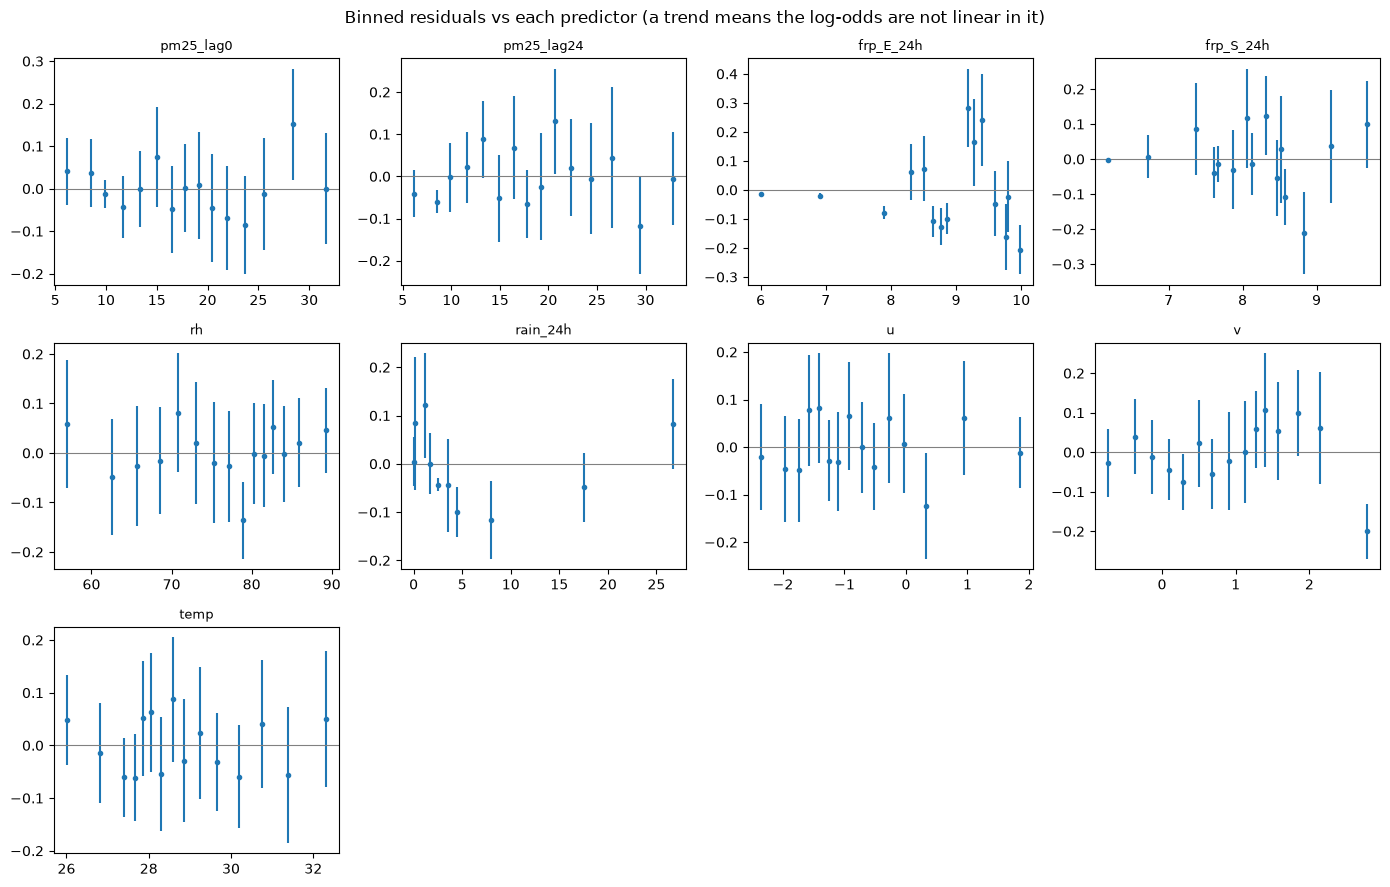

In [18]:
cont = explore + (["temp"] if WEATHER_OK else [])
fig, axes = plt.subplots(int(np.ceil(len(cont) / 4)), 4, figsize=(14, 3 * int(np.ceil(len(cont) / 4))))
for ax, v in zip(axes.flat, cont):
    bx, br, bse = binned(train[v], train["high"] - p_fit, k=15)
    ax.errorbar(bx, br, yerr=bse, fmt="o", ms=3); ax.axhline(0, c="grey", lw=0.8); ax.set_title(v, fontsize=9)
for ax in list(axes.flat)[len(cont):]:
    ax.axis("off")
fig.suptitle("Binned residuals vs each predictor (a trend means the log-odds are not linear in it)"); plt.tight_layout(); plt.show()

In [19]:
# the most influential training hours
pd.DataFrame({"y": train["y"], "high": train["high"], "p_fit": p_fit, "leverage": lev, "cooks_d": cooks},
             index=train.index).sort_values("cooks_d", ascending=False).head(8).round(3)

,y,high,p_fit,leverage,cooks_d
timestamp,,,,,
2023-09-25 03:00:00+08:00,25.0,1.0,0.030,0.027,0.062
2023-09-25 06:00:00+08:00,26.0,1.0,0.022,0.018,0.057
2023-09-25 07:00:00+08:00,29.0,1.0,0.026,0.020,0.053
2023-10-11 06:00:00+08:00,27.0,1.0,0.040,0.024,0.039
2023-09-24 20:00:00+08:00,27.2,1.0,0.122,0.067,0.037
2023-09-24 19:00:00+08:00,25.8,1.0,0.071,0.033,0.031
2023-09-25 13:00:00+08:00,25.4,1.0,0.038,0.015,0.025
2023-10-10 22:00:00+08:00,27.6,1.0,0.077,0.022,0.018


# 7. Validation inside the training period (rolling origin)

For each day from 1 to 14 October, every predictor is refitted on the rows whose target is before that day and then forecasts that day's 24 hours, as in the linear notebook. Scores:

- **Brier score** = mean (p − y)², lower is better; **skill vs persistence** = 1 − Brier / Brier(persistence) is the headline;
- **log loss**, for probabilistic forecasts only (persistence gives 0/1, so its log loss is infinite);
- **AUC**: probability that a random high hour gets a higher forecast than a random non-high hour.

The probability cut-off used to turn forecasts into yes/no warnings is also chosen here, on validation data only.

In [20]:
def logit_predictor(formula):
    def f(fit_rows, new):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            return smf.logit(formula, data=fit_rows).fit(disp=0, maxiter=200).predict(new)
    return f

def persistence(fit_rows, new):
    return (new["pm25_lag0"] >= THRESHOLD).astype(float)

def climatology(fit_rows, new):
    return pd.Series(fit_rows["high"].mean(), index=new.index)

def hourly_climatology(fit_rows, new):
    by_hour = fit_rows.groupby(fit_rows["target_time"].dt.hour)["high"].mean()
    return pd.Series(new["target_time"].dt.hour.map(by_hour).to_numpy(), index=new.index)

predictors = {"Persistence": persistence, "Climatology (base rate)": climatology, "Hourly climatology": hourly_climatology}
predictors.update({name: logit_predictor(f) for name, f in formulas.items()})

def rolling_origin(data, days):
    out = []
    for day in days:
        fit_rows = data[data["target_time"] < day]
        new = data[(data.index >= day) & (data.index < day + pd.Timedelta(days=1))]
        if len(new) == 0:
            continue
        preds = pd.DataFrame({name: f(fit_rows, new) for name, f in predictors.items()})
        preds.insert(0, "high", new["high"]); preds.insert(0, "y", new["y"]); preds.insert(0, "day", day)
        out.append(preds)
    return pd.concat(out)

val_days = pd.date_range("2023-10-01", "2023-10-14", freq="D", tz=SGT)
val = rolling_origin(train, val_days)
print(f"{len(val)} validation forecasts over {val['day'].nunique()} days, {int(val['high'].sum())} high hours")

227 validation forecasts over 11 days, 53 high hours


In [21]:
def auc(y, p):
    # Mann-Whitney form; ties count one half
    r = stats.rankdata(p)
    n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0) if n1 and n0 else np.nan

def scores(df, names):
    brier_persist = np.mean((df["Persistence"] - df["high"]) ** 2)
    rows = {}
    for name in names:
        p, y = df[name], df["high"]
        hard = name == "Persistence"
        pc = p.clip(1e-6, 1 - 1e-6)
        daily = ((p - y) ** 2).groupby(df["day"]).mean()
        rows[name] = {"Brier": np.mean((p - y) ** 2),
                      "skill_vs_persistence": 1 - np.mean((p - y) ** 2) / brier_persist,
                      "log_loss": np.nan if hard else -np.mean(y * np.log(pc) + (1 - y) * np.log(1 - pc)),
                      "AUC": auc(y.to_numpy(), p.to_numpy()),
                      "daily_Brier_max": daily.max()}
    return pd.DataFrame(rows).T

validation_scores = scores(val, predictors)
validation_scores.round(3)

,Brier,skill_vs_persistence,log_loss,AUC,daily_Brier_max
Persistence,0.396,0.000,NaN,0.459,1.000
Climatology (base rate),0.184,0.536,0.559,0.406,0.666
Hourly climatology,0.180,0.546,0.550,0.560,0.713
Season only,0.189,0.524,0.598,0.471,0.689
Baseline (persistence + season),0.288,0.273,0.821,0.375,0.764
+ Weather,0.317,0.200,0.901,0.358,0.715
+ Weather + Fire,0.252,0.365,0.842,0.457,0.727
+ Weather + Fire + Transport,0.236,0.404,0.776,0.481,0.601


## Choosing the warning cut-off on validation data

A forecast p becomes a "high tomorrow" warning when p ≥ c. We pick the c that maximises the **Peirce skill score** (hit rate − false alarm rate) for the full model over the validation forecasts, then use it unchanged on the test set. F1 is not used for this: with about one validation hour in four high, "always warn" already scores F1 ≈ 0.38, so maximising F1 picks the lowest cut-off. The Peirce score of "always warn" or "never warn" is 0. Persistence needs no cut-off.

In [22]:
def classify(y, warn):
    tp = int(((warn == 1) & (y == 1)).sum()); fp = int(((warn == 1) & (y == 0)).sum())
    fn = int(((warn == 0) & (y == 1)).sum()); tn = int(((warn == 0) & (y == 0)).sum())
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan
    f1 = 2 * precision * recall / (precision + recall) if tp else 0.0
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn, "precision": precision, "recall (hit rate)": recall,
            "false_alarm_rate": fp / (fp + tn) if fp + tn else np.nan, "F1": f1,
            "Peirce": (tp / (tp + fn) if tp + fn else 0) - (fp / (fp + tn) if fp + tn else 0)}

cuts = np.round(np.arange(0.05, 0.96, 0.05), 2)
peirce_by_cut = pd.Series({c: classify(val["high"], (val[FULL] >= c).astype(int))["Peirce"] for c in cuts})
CUTOFF = float(peirce_by_cut.idxmax())
print(f"cut-off chosen on validation: p ≥ {CUTOFF:.2f} (Peirce = {peirce_by_cut.max():.3f}; at 0.50 Peirce = {peirce_by_cut.loc[0.5]:.3f})")
print(f"persistence on the same validation hours: Peirce = {classify(val['high'], val['Persistence'].astype(int))['Peirce']:.3f}")

cut-off chosen on validation: p ≥ 0.05 (Peirce = 0.027; at 0.50 Peirce = 0.020)
persistence on the same validation hours: Peirce = -0.081


## Variable selection: which variables, and from which data source?

The model ladder above adds whole data sources in a fixed order. Here the question is asked **one variable at a time**: among the variables the three data sources provide, which ones actually improve out-of-sample forecasts, and does the best set need all sources or just one?

- **Always kept:** the calendar terms `hour_sin`, `hour_cos` and `is_weekend`. They come from the clock, not from a data source, and they define the season baseline.
- **Candidates:** the other variables of the full model. Each one is tagged with the data source it comes from (table below).
- **Rules:** every choice is made on the training period, with the same rolling-origin folds (1–14 Oct). The final test is used once, in section 8, where the selected model is scored alongside the ladder.

### Subset-selection methods available

**A. Search strategies: which subsets to try**

| method | how it works | models fitted (p candidates) | notes |
|---|---|---|---|
| **Best subset (exhaustive)** | fit every combination; keep the best model of each size | 2^p | exact; feasible here (p = 11 → 2,048 models) |
| Leaps-and-bounds / branch-and-bound | best subset that skips subsets which cannot win | far fewer than 2^p | same answer as best subset, only faster; not needed at this size |
| **Forward stepwise** | start empty, add the variable that improves the fit most, repeat | about p²/2 | greedy: can miss the best subset |
| **Backward stepwise** | start full, remove the least useful variable, repeat | about p²/2 | needs n > p (here n ≈ 590) |
| Hybrid (bidirectional) stepwise | forward steps that may also drop a variable added earlier | about p² | between forward and backward |
| Forward stagewise | many tiny coefficient updates | many small steps | close to the lasso path; mainly of theoretical interest |

**B. Criteria: how to pick the winner or the model size**

| criterion | type | use |
|---|---|---|
| RSS / R² (linear), log-likelihood (logistic) | in-sample | only to compare models **of the same size**; always prefers bigger models |
| Mallows' Cp, AIC, BIC, adjusted R² | in-sample, penalised | BIC penalises most, so it picks smaller models |
| Validation set / cross-validation | out-of-sample | the fairest; for time series it must be **time-ordered** (rolling origin), never random k-fold |

**C. Shrinkage methods that also select**

| method | what it does |
|---|---|
| **Lasso** | an L1 penalty sets some coefficients exactly to zero |
| Elastic net | lasso + ridge; keeps groups of correlated variables together |
| Adaptive lasso | lasso with per-variable weights; less biased |
| Relaxed lasso | lasso chooses the variables, then an unpenalised refit |
| Group lasso | keeps or drops whole groups (e.g. all variables of one source) |
| LARS | an algorithm that computes the whole lasso path cheaply |

**D. Supporting techniques**

- **Stability selection:** repeat the selection over many folds or resamples and count how often each variable is kept.
- **Screening** (e.g. sure independence screening): drop clearly useless variables first; only needed when p is very large.
- Not selection methods: ridge regression keeps every variable; PCR and PLS build combinations of variables instead of choosing among them.

### Why we use best subset + forward/backward + lasso + stability counts

1. **Best subset is the main method.** With p = 11 every subset can be fitted, so there is no reason to accept an approximation. For each size, the best model is the one with the smallest training RSS (linear) or highest log-likelihood (logistic). Comparing models of the *same* size this way is fair.
2. **The size is chosen by time-ordered cross-validation**, using the same rolling-origin folds as the ladder (RMSE for linear, Brier score for logistic). Training fit always improves as variables are added, so it cannot choose the size. Random k-fold would mix future and past hours, which leaks information through the strong hour-to-hour autocorrelation. BIC is shown next to the CV curve as an in-sample cross-check.
3. **Forward and backward stepwise are run for comparison.** They are the greedy shortcuts used when best subset is too expensive. If they reach the same variables, the result does not depend on the search method. If they disagree, that shows the selection is fragile.
4. **Lasso is the shrinkage counterpart.** It selects by penalising coefficients instead of searching subsets, and treats correlated inputs differently (it tends to keep one of a correlated pair and shrink the other). Candidates are standardised inside each fold, using that fold's training rows only, so the penalty treats every variable on the same scale. The calendar terms are not penalised. The penalty is chosen by the same rolling-origin CV.
5. **Stability counts** rerun forward stepwise (at the chosen size) and the lasso (at the chosen penalty) in each rolling-origin fold (one per validation day with data, 11 here) and record how often each variable is kept. A variable kept in nearly every fold is a robust finding; one kept in half the folds is not.
6. **The test period is not touched** by any of this. The best-subset model is handed to the final-test section and scored once.

**Caveats to state in the report**

- **p-values of a selected model are not valid.** Selecting variables and then testing them on the same data makes them look more significant than they are. Formal evidence for the fire terms stays with the pre-specified nested tests (F / likelihood-ratio and HAC Wald) earlier in the notebook. Selection is used here to *describe* which variables help forecasts.
- **Correlated variables can swap.** Temperature and humidity move together, and so do the two fire sectors and fire vs. transport. "Not selected" does not mean "no effect"; it can mean "already covered by a correlated variable".
- **One haze episode.** Most of the fire signal comes from early October 2023, so the selection can change with more haze seasons.

In [23]:
import warnings
from itertools import combinations

LOGIT = True
RESP = formulas[FULL].split("~")[0].strip()          # "y" (linear) or "high" (logistic)
SEASON_TERMS = [t.strip() for t in season.split("+")]
CANDIDATES = [t.strip() for t in formulas[FULL].split("~")[1].split("+") if t.strip() not in SEASON_TERMS]

def source_of(v):
    if v.startswith("pm25"): return "PM2.5 (NEA, data.gov.sg)"
    if v.startswith("frp_"): return "Fires (NASA FIRMS)"
    if v.startswith("transport_"): return "Fires × Weather"
    return "Weather (data.gov.sg)"

SOURCE = {v: source_of(v) for v in CANDIDATES}
SOURCES = list(dict.fromkeys(SOURCE.values()))
COLOR = {"PM2.5 (NEA, data.gov.sg)": "#4C72B0", "Weather (data.gov.sg)": "#55A868",
         "Fires (NASA FIRMS)": "#C44E52", "Fires × Weather": "#DD8452"}
LIGHT = {"PM2.5 (NEA, data.gov.sg)": "#dbe4f2", "Weather (data.gov.sg)": "#dcefe0",
         "Fires (NASA FIRMS)": "#f4dada", "Fires × Weather": "#f8e6d6"}
p = len(CANDIDATES)
print(f"{p} candidates -> {2 ** p:,} subsets; always kept: {SEASON_TERMS}")
pd.DataFrame({"data source": SOURCE}).rename_axis("variable")

11 candidates -> 2,048 subsets; always kept: ['hour_sin', 'hour_cos', 'is_weekend']


,data source
variable,
pm25_lag0,"PM2.5 (NEA, data.gov.sg)"
pm25_lag24,"PM2.5 (NEA, data.gov.sg)"
temp,Weather (data.gov.sg)
rh,Weather (data.gov.sg)
rain_24h,Weather (data.gov.sg)
u,Weather (data.gov.sg)
v,Weather (data.gov.sg)
frp_E_24h,Fires (NASA FIRMS)
frp_S_24h,Fires (NASA FIRMS)


### Best subset, forward and backward stepwise

For every size k = 0 … p, each search keeps the model with the best training fit. That is the lowest RSS for linear, or the highest log-likelihood for logistic. Size 0 is the calendar-only model and size p is the full model, so both ends must reproduce models already fitted in the ladder; this is checked below.

In [24]:
def arrays(rows):
    return (rows[RESP].to_numpy(float), sm.add_constant(rows[SEASON_TERMS].to_numpy(float), has_constant="add"),
            rows[CANDIDATES].to_numpy(float))

def fit_score(cols, data):
    """Training loss (RSS, or minus the log-likelihood) of calendar + the candidate columns `cols`."""
    y, Xcal, Xc = data
    X = np.column_stack([Xcal, Xc[:, list(cols)]]) if cols else Xcal
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            r = sm.Logit(y, X).fit(disp=0, maxiter=200) if LOGIT else sm.OLS(y, X).fit()
        except Exception:                      # e.g. perfect separation in a logistic fit
            return np.inf, None
    return (-r.llf if LOGIT else r.ssr), r

def stepwise(data, forward=True):
    cur = [] if forward else list(range(p))
    path = {len(cur): tuple(cur)}
    while (len(cur) < p) if forward else cur:
        options = [j for j in range(p) if j not in cur] if forward else cur
        trials = [(fit_score(sorted(cur + [j]) if forward else [c for c in cur if c != j], data)[0], j) for j in options]
        j = min(trials)[1]
        cur = sorted(cur + [j]) if forward else [c for c in cur if c != j]
        path[len(cur)] = tuple(cur)
    return path

train_arrays = arrays(train)
best = {}
for k in range(p + 1):
    for cols in combinations(range(p), k):
        s, r = fit_score(cols, train_arrays)
        if k not in best or s < best[k][0]:
            best[k] = (s, cols, r)
paths = {"Best subset": {k: best[k][1] for k in best},
         "Forward": stepwise(train_arrays, True),
         "Backward": stepwise(train_arrays, False)}

# self-checks: both ends equal models already in the ladder, and the greedy paths share those ends
fit = (lambda f: smf.logit(f, train).fit(disp=0, maxiter=200)) if LOGIT else (lambda f: smf.ols(f, train).fit())
loss = (lambda r: -r.llf) if LOGIT else (lambda r: r.ssr)
assert np.isclose(best[p][0], loss(fit(formulas[FULL]))), "full-size subset differs from the full model"
assert np.isclose(best[0][0], loss(fit(formulas["Season only"]))), "size-0 subset differs from 'Season only'"
assert all(pth[0] == () and pth[p] == tuple(range(p)) for pth in paths.values())

names = lambda cols: ", ".join(CANDIDATES[j] for j in cols) or "(calendar only)"
in_sample = pd.DataFrame({k: {"best subset": names(best[k][1]),
                              ("McFadden R²" if LOGIT else "adj R²"): best[k][2].prsquared if LOGIT else best[k][2].rsquared_adj,
                              "AIC": best[k][2].aic, "BIC": best[k][2].bic} for k in best}).T.rename_axis("size")
in_sample

,best subset,McFadden R²,AIC,BIC
size,,,,
0,(calendar only),0.009754,588.642524,606.142623
1,frp_S_24h,0.187358,486.501963,508.377087
2,"pm25_lag24, frp_S_24h",0.222742,467.754388,494.004537
3,"pm25_lag24, rh, frp_S_24h",0.236181,461.874119,492.499293
4,"pm25_lag24, temp, rh, frp_S_24h",0.253845,453.516723,488.516921
5,"pm25_lag24, temp, rh, frp_E_24h, frp_S_24h",0.269715,446.21125,485.586473
6,"pm25_lag24, temp, rh, frp_E_24h, frp_S_24h, tr...",0.272952,446.313169,490.063417
7,"pm25_lag24, temp, rh, v, frp_E_24h, frp_S_24h,...",0.27488,447.182394,495.307667
8,"pm25_lag24, temp, rh, rain_24h, v, frp_E_24h, ...",0.275792,448.648073,501.14837


### Choosing the size by rolling-origin cross-validation

Each model on each path is refitted every validation day, using only rows whose target comes before that day, exactly as in the ladder comparison. The chosen size is the one with the lowest validation error on the best-subset path.

In [25]:
make = logit_predictor if LOGIT else ols_predictor
formula_of = lambda cols: f"{RESP} ~ " + " + ".join(SEASON_TERMS + [CANDIDATES[j] for j in cols])
METRIC = "Brier" if LOGIT else "RMSE"

def folds(rows=train):
    for day in val_days:
        new = rows[(rows.index >= day) & (rows.index < day + pd.Timedelta(days=1))]
        if len(new):
            yield rows[rows["target_time"] < day], new

def summarise(err):
    e = pd.concat(err)
    return float((e ** 2).mean()) if LOGIT else float(np.sqrt((e ** 2).mean()))

_cv = {}
def cv_error(cols):
    cols = tuple(sorted(cols))
    if cols not in _cv:
        f = make(formula_of(cols))
        _cv[cols] = summarise([new[RESP] - f(fit_rows, new) for fit_rows, new in folds()])
    return _cv[cols]

cv_table = pd.DataFrame({name: {k: cv_error(cols) for k, cols in pth.items()} for name, pth in paths.items()}).rename_axis("size")
K_BEST = int(cv_table["Best subset"].idxmin())
K_PATH = {name: int(cv_table[name].idxmin()) for name in paths}
print(f"validation {METRIC} by size; chosen size (best subset) = {K_BEST}: {names(best[K_BEST][1])}")
print(f"forward picks size {K_PATH['Forward']}: {names(paths['Forward'][K_PATH['Forward']])}")
print(f"backward picks size {K_PATH['Backward']}: {names(paths['Backward'][K_PATH['Backward']])}")
cv_table.assign(BIC=in_sample["BIC"].astype(float)).round(4)

validation Brier by size; chosen size (best subset) = 1: frp_S_24h
forward picks size 1: frp_S_24h
backward picks size 1: frp_S_24h


,Best subset,Forward,Backward,BIC
size,,,,
0,0.1887,0.1887,0.1887,606.1426
1,0.1789,0.1789,0.1789,508.3771
2,0.1793,0.1793,0.1793,494.0045
3,0.1854,0.1854,0.1854,492.4993
4,0.1943,0.1943,0.1943,488.5169
5,0.1894,0.1894,0.1894,485.5865
6,0.2267,0.2267,0.2267,490.0634
7,0.2117,0.2117,0.2117,495.3077
8,0.2161,0.2161,0.2161,501.1484


### Lasso

The candidates are standardised inside every fold with that fold's own training mean and standard deviation, so no information from the predicted day leaks into the scaling. The calendar terms and the intercept are not penalised. The penalty α is chosen by the same rolling-origin CV, then the lasso is refitted on the whole training period at that α to read off which variables survive.

In [26]:
ALPHAS = np.logspace(-4, -0.5, 20) if LOGIT else np.logspace(-3, 0.7, 20)

def lasso_fit(rows, alpha):
    mu, sd = rows[CANDIDATES].mean(), rows[CANDIDATES].std()
    X = sm.add_constant(pd.concat([rows[SEASON_TERMS], (rows[CANDIDATES] - mu) / sd], axis=1), has_constant="add").astype(float)
    pen = np.r_[np.zeros(1 + len(SEASON_TERMS)), np.full(p, alpha)]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if LOGIT:   # Logit's L1 objective is a sum over rows, OLS's is a mean, so scale α by n to match
            r = sm.Logit(rows[RESP].astype(float), X).fit_regularized(method="l1", alpha=pen * len(rows), disp=0)
        else:
            r = sm.OLS(rows[RESP].astype(float), X).fit_regularized(method="elastic_net", L1_wt=1.0, alpha=pen, maxiter=1000)  # default 50 does not converge
    return pd.Series(np.asarray(r.params), index=X.columns), mu, sd

def lasso_predict(params, mu, sd, new):
    X = sm.add_constant(pd.concat([new[SEASON_TERMS], (new[CANDIDATES] - mu) / sd], axis=1), has_constant="add").astype(float)
    eta = X.to_numpy() @ params.to_numpy()
    return pd.Series(1 / (1 + np.exp(-eta)) if LOGIT else eta, index=new.index)

if not LOGIT:   # self-check: with α = 0 the lasso is ordinary least squares
    par, mu, sd = lasso_fit(train, 0.0)
    assert np.allclose(lasso_predict(par, mu, sd, train), smf.ols(formulas[FULL], train).fit().fittedvalues, atol=1e-2)

lasso_cv = pd.Series({a: summarise([new[RESP] - lasso_predict(*lasso_fit(fit_rows, a), new) for fit_rows, new in folds()])
                      for a in ALPHAS}, name=f"validation {METRIC}")
ALPHA = float(lasso_cv.idxmin())
lasso_path = pd.DataFrame({a: lasso_fit(train, a)[0][CANDIDATES] for a in ALPHAS}).T
lasso_kept = lasso_path.loc[ALPHA].abs() > 1e-8
print(f"chosen α = {ALPHA:.4g} (validation {METRIC} {lasso_cv.min():.4f}); "
      f"kept {int(lasso_kept.sum())} of {p}: {', '.join(lasso_kept.index[lasso_kept])}")
lasso_cv.round(4).to_frame().T

chosen α = 0.08859 (validation Brier 0.1835); kept 1 of 11: frp_S_24h


,0.000100,0.000153,0.000234,0.000357,0.000546,0.000834,0.001274,0.001947,0.002976,0.004549,0.006952,0.010625,0.016238,0.024816,0.037927,0.057964,0.088587,0.135388,0.206914,0.316228
validation Brier,0.2197,0.2343,0.2385,0.2301,0.2374,0.2344,0.2346,0.23,0.2253,0.22,0.2114,0.2,0.1903,0.1835,0.1837,0.184,0.1835,0.1866,0.1887,0.1887


### Stability across the rolling-origin folds

The selection is repeated on each fold's training rows: forward stepwise stopped at the size chosen above, and the lasso at the chosen α. The table counts how often each variable is kept.

In [27]:
fold_list = list(folds())
stab_fwd = pd.Series(0, index=CANDIDATES); stab_lasso = pd.Series(0, index=CANDIDATES)
for fit_rows, _ in fold_list:
    for j in stepwise(arrays(fit_rows), True)[K_PATH["Forward"]]:
        stab_fwd[CANDIDATES[j]] += 1
    stab_lasso += (lasso_fit(fit_rows, ALPHA)[0][CANDIDATES].abs() > 1e-8).astype(int)
stability = pd.DataFrame({"forward, % of folds": 100 * stab_fwd / len(fold_list),
                          "lasso, % of folds": 100 * stab_lasso / len(fold_list)})
print(f"{len(fold_list)} folds")

11 folds


### Summary: selected variables by data source (report table)

Each row is one candidate variable, coloured by its data source. ✓ means the method keeps the variable at its CV-chosen size or penalty.

The second table answers the source-level question with the same CV folds:
- **only this source:** the calendar plus every variable of that one source;
- **all sources:** the full model;
- **selected:** the best-subset model;
- **+ error if removed:** how much the selected model's validation error rises if that source's variables are taken out. A positive value means the source is needed.

In [28]:
kept = lambda cols: [j in cols for j in range(p)]
sel = pd.DataFrame({"data source": [SOURCE[v] for v in CANDIDATES],
                    "best subset": kept(best[K_BEST][1]),
                    "forward": kept(paths["Forward"][K_PATH["Forward"]]),
                    "backward": kept(paths["Backward"][K_PATH["Backward"]]),
                    "lasso": lasso_kept.to_numpy()}, index=pd.Index(CANDIDATES, name="variable")).join(stability.round(0))
sel = sel.sort_values("data source", key=lambda s: s.map(SOURCES.index), kind="stable")

chosen = best[K_BEST][1]
src_rows = {}
for s in SOURCES:
    own = [j for j in range(p) if SOURCE[CANDIDATES[j]] == s]
    rest = [j for j in chosen if j not in own]
    src_rows[s] = {"variables available": len(own), "kept by best subset": sum(j in chosen for j in own),
                   "kept by lasso": int(lasso_kept.iloc[own].sum()),
                   f"CV {METRIC}, only this source": cv_error(own),
                   f"+ {METRIC} if removed from selected": cv_error(rest) - cv_error(chosen) if len(rest) < len(chosen) else 0.0}
by_source = pd.DataFrame(src_rows).T.rename_axis("data source")
COUNTS = ["variables available", "kept by best subset", "kept by lasso"]
by_source[COUNTS] = by_source[COUNTS].astype(int)
print(f"validation {METRIC}: calendar only {cv_error(()):.4f} | all sources {cv_error(range(p)):.4f} | "
      f"selected ({K_BEST} variables) {cv_error(chosen):.4f}")
print(sel.replace({True: "✓", False: ""}).to_string()); print(); print(by_source.round(4).to_string())

shade = lambda row: [f"background-color: {LIGHT[row['data source']]}"] * len(row)
display(sel.replace({True: "✓", False: ""}).style.apply(shade, axis=1).format(precision=0)
           .set_caption("Selected variables, coloured by data source"))
display(by_source.style.apply(lambda r: [f"background-color: {LIGHT[r.name]}"] * len(r), axis=1).format(precision=4)
           .set_caption("By data source (validation folds 1–14 Oct)"))

validation Brier: calendar only 0.1887 | all sources 0.2363 | selected (1 variables) 0.1789
                          data source best subset forward backward lasso  forward, % of folds  lasso, % of folds
variable                                                                                                        
pm25_lag0    PM2.5 (NEA, data.gov.sg)                                                     0.0               36.0
pm25_lag24   PM2.5 (NEA, data.gov.sg)                                                     0.0               73.0
temp            Weather (data.gov.sg)                                                     0.0                0.0
rh              Weather (data.gov.sg)                                                     0.0                0.0
rain_24h        Weather (data.gov.sg)                                                     0.0                0.0
u               Weather (data.gov.sg)                                                     0.0                0.0
v   

,data source,best subset,forward,backward,lasso,"forward, % of folds","lasso, % of folds"
variable,,,,,,,
pm25_lag0,"PM2.5 (NEA, data.gov.sg)",,,,,0,36
pm25_lag24,"PM2.5 (NEA, data.gov.sg)",,,,,0,73
temp,Weather (data.gov.sg),,,,,0,0
rh,Weather (data.gov.sg),,,,,0,0
rain_24h,Weather (data.gov.sg),,,,,0,0
u,Weather (data.gov.sg),,,,,0,0
v,Weather (data.gov.sg),,,,,0,0
frp_E_24h,Fires (NASA FIRMS),,,,,0,0
frp_S_24h,Fires (NASA FIRMS),✓,✓,✓,✓,100,100


,variables available,kept by best subset,kept by lasso,"CV Brier, only this source",+ Brier if removed from selected
data source,,,,,
"PM2.5 (NEA, data.gov.sg)",2,0,0,0.2884,0.0000
Weather (data.gov.sg),5,0,0,0.1956,0.0000
Fires (NASA FIRMS),2,1,1,0.1787,0.0098
Fires × Weather,2,0,0,0.1891,0.0000


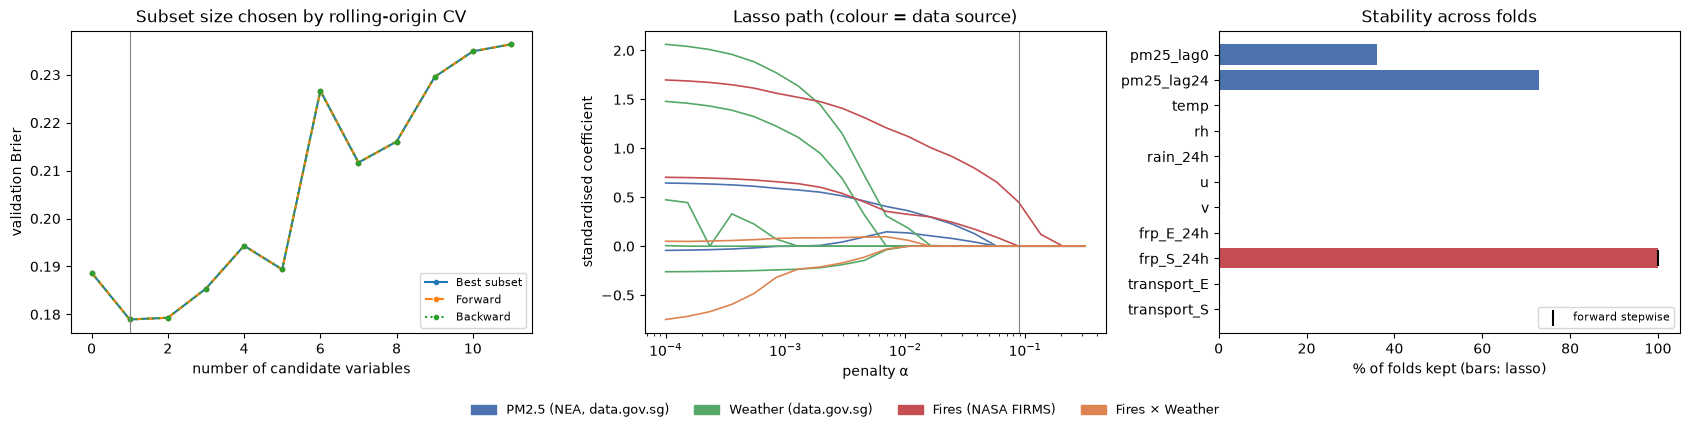

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for name, ls in zip(paths, ["-", "--", ":"]):
    ax[0].plot(cv_table.index, cv_table[name], ls, marker="o", ms=3, label=name)
ax[0].axvline(K_BEST, color="grey", lw=0.8)
ax[0].set(xlabel="number of candidate variables", ylabel=f"validation {METRIC}", title="Subset size chosen by rolling-origin CV")
ax[0].legend(fontsize=8)
for v in CANDIDATES:
    ax[1].plot(lasso_path.index, lasso_path[v], color=COLOR[SOURCE[v]], lw=1.2)
ax[1].axvline(ALPHA, color="grey", lw=0.8)
ax[1].set(xscale="log", xlabel="penalty α", ylabel="standardised coefficient", title="Lasso path (colour = data source)")
order = sel.index[::-1]
ax[2].barh(order, sel.loc[order, "lasso, % of folds"], color=[COLOR[SOURCE[v]] for v in order])
ax[2].scatter(sel.loc[order, "forward, % of folds"], order, marker="|", s=120, c="k", label="forward stepwise")
ax[2].set(xlim=(0, 105), xlabel="% of folds kept (bars: lasso)", title="Stability across folds"); ax[2].legend(fontsize=8, loc="lower right")
handles = [plt.Rectangle((0, 0), 1, 1, color=COLOR[s]) for s in SOURCES]
fig.legend(handles, SOURCES, loc="lower center", ncol=len(SOURCES), fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1)); fig.savefig(FIG / "logistic_selection.png", dpi=150, bbox_inches="tight"); plt.show()

### Hand-off to the final test

The best-subset model at the CV-chosen size is added to the list of models, so the final-test section below scores it once, together with the ladder. Its warnings use the cut-off chosen on validation for the full model. This is the only time its test performance is looked at.

In [30]:
SELECTED = "Best subset (CV)"
formulas[SELECTED] = formula_of(best[K_BEST][1])
predictors[SELECTED] = make(formulas[SELECTED])
print(f"{SELECTED}: {formulas[SELECTED]}")

Best subset (CV): high ~ hour_sin + hour_cos + is_weekend + frp_S_24h


# 8. Prediction and out-of-sample evaluation (final test, used once)

All models are refitted on the full training period and forecast every test hour. This is the only time the test labels are used.

In [31]:
test_pred = pd.DataFrame({name: f(train, test) for name, f in predictors.items()}, index=test.index)
test_pred.insert(0, "high", test["high"]); test_pred.insert(0, "y", test["y"]); test_pred.insert(0, "day", test.index.floor("D"))
print(f"test: {len(test_pred)} forecast hours, {int(test_pred['high'].sum())} high ({test_pred['high'].mean():.1%}; "
      f"training base rate {train['high'].mean():.1%})")

# persistence Brier = its misclassification rate, computed by hand as a check
assert np.isclose(np.mean((test_pred["Persistence"] - test_pred["high"]) ** 2),
                  np.mean((test["pm25_lag0"] >= THRESHOLD) != (test["y"] >= THRESHOLD)))

test_scores = scores(test_pred, predictors)
test_scores.round(3)

test: 334 forecast hours, 12 high (3.6%; training base rate 19.9%)


,Brier,skill_vs_persistence,log_loss,AUC,daily_Brier_max
Persistence,0.045,0.000,NaN,0.495,0.304
Climatology (base rate),0.061,-0.366,0.272,0.500,0.223
Hourly climatology,0.069,-0.528,0.284,0.433,0.238
Season only,0.064,-0.422,0.277,0.395,0.244
Baseline (persistence + season),0.050,-0.123,0.226,0.488,0.270
+ Weather,0.041,0.077,0.187,0.496,0.281
+ Weather + Fire,0.079,-0.763,0.258,0.824,0.410
+ Weather + Fire + Transport,0.082,-0.831,0.267,0.803,0.467
Best subset (CV),0.091,-1.023,0.298,0.811,0.401


In [32]:
warn_rules = {"Persistence": test_pred["Persistence"].astype(int)}
warn_rules.update({f"{n} (p ≥ {CUTOFF:.2f})": (test_pred[n] >= CUTOFF).astype(int) for n in formulas})
pd.DataFrame({n: classify(test_pred["high"], w) for n, w in warn_rules.items()}).T.round(3)

,TP,FP,FN,TN,precision,recall (hit rate),false_alarm_rate,F1,Peirce
Persistence,0.0,3.0,12.0,319.0,0.000,0.000,0.009,0.000,-0.009
Season only (p ≥ 0.05),12.0,322.0,0.0,0.0,0.036,1.000,1.000,0.069,0.000
Baseline (persistence + season) (p ≥ 0.05),12.0,322.0,0.0,0.0,0.036,1.000,1.000,0.069,0.000
+ Weather (p ≥ 0.05),6.0,240.0,6.0,82.0,0.024,0.500,0.745,0.047,-0.245
+ Weather + Fire (p ≥ 0.05),10.0,120.0,2.0,202.0,0.077,0.833,0.373,0.141,0.461
+ Weather + Fire + Transport (p ≥ 0.05),10.0,116.0,2.0,206.0,0.079,0.833,0.360,0.145,0.473
Best subset (CV) (p ≥ 0.05),11.0,229.0,1.0,93.0,0.046,0.917,0.711,0.087,0.205


## ROC curves and calibration on the test period

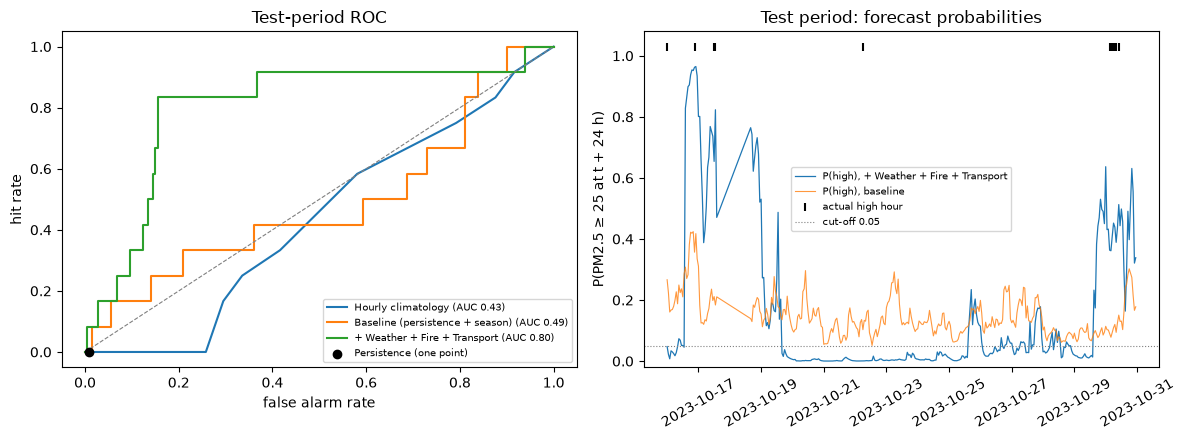

In [33]:
def roc(y, p):
    thr = np.r_[np.inf, np.sort(np.unique(p))[::-1]]
    return [((p >= t) & (y == 0)).sum() / max((y == 0).sum(), 1) for t in thr], [((p >= t) & (y == 1)).sum() / max((y == 1).sum(), 1) for t in thr]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
yv = test_pred["high"].to_numpy()
for name in ["Hourly climatology", "Baseline (persistence + season)", FULL]:
    fpr, tpr = roc(yv, test_pred[name].to_numpy())
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {test_scores.loc[name, 'AUC']:.2f})")
pr = classify(test_pred["high"], test_pred["Persistence"].astype(int))
ax[0].scatter(pr["false_alarm_rate"], pr["recall (hit rate)"], c="k", zorder=3, label="Persistence (one point)")
ax[0].plot([0, 1], [0, 1], ls="--", c="grey", lw=0.8); ax[0].legend(fontsize=7)
ax[0].set(title="Test-period ROC", xlabel="false alarm rate", ylabel="hit rate")

ax[1].plot(test_pred.index, test_pred[FULL], lw=0.9, label=f"P(high), {FULL}")
ax[1].plot(test_pred.index, test_pred["Baseline (persistence + season)"], lw=0.8, alpha=0.8, label="P(high), baseline")
ax[1].scatter(test_pred.index[yv == 1], np.ones((yv == 1).sum()) * 1.03, marker="|", c="k", label="actual high hour")
ax[1].axhline(CUTOFF, ls=":", c="grey", lw=0.8, label=f"cut-off {CUTOFF:.2f}")
ax[1].set(title="Test period: forecast probabilities", ylabel="P(PM2.5 ≥ 25 at t + 24 h)", ylim=(-0.02, 1.08)); ax[1].legend(fontsize=7)
ax[1].tick_params(axis="x", labelrotation=30)
plt.tight_layout(); fig.savefig(FIG / "logistic_test.png", dpi=150, bbox_inches="tight"); plt.show()

## Uncertainty of the improvement over persistence

Block bootstrap over whole test days (as in the linear notebook): the difference Brier(model) − Brier(persistence). Negative means the model is better. With few high hours in the test period the interval is wide.

In [34]:
rng = np.random.default_rng(42)
days = test_pred["day"].unique()
by_day = {d: test_pred.index[test_pred["day"] == d] for d in days}
sq = {name: (test_pred[name] - test_pred["high"]) ** 2 for name in predictors}

def boot_brier_diff(name, B=2000):
    diffs = []
    for _ in range(B):
        idx = np.concatenate([by_day[d] for d in rng.choice(days, size=len(days), replace=True)])
        diffs.append(sq[name].loc[idx].mean() - sq["Persistence"].loc[idx].mean())
    return np.percentile(diffs, [2.5, 50, 97.5])

boot = pd.DataFrame({n: boot_brier_diff(n) for n in formulas}, index=["2.5%", "median", "97.5%"]).T
boot.columns.name = "Brier(model) − Brier(persistence)"
boot.round(4)

Brier(model) − Brier(persistence),2.5%,median,97.5%
Season only,-0.0021,0.0194,0.0372
Baseline (persistence + season),-0.0076,0.0059,0.0165
+ Weather,-0.0148,-0.0034,0.0061
+ Weather + Fire,-0.0031,0.0334,0.0826
+ Weather + Fire + Transport,0.0001,0.0354,0.0848
Best subset (CV),0.0144,0.0452,0.0782


## Largest test errors (failure cases)

In [35]:
worst = test_pred.assign(error=test_pred["high"] - test_pred[FULL])
worst.reindex(worst["error"].abs().sort_values(ascending=False).index)[["y", "high", FULL, "Persistence", "error"]].head(10).round(3)

,y,high,+ Weather + Fire + Transport,Persistence,error
timestamp,,,,,
2023-10-22 06:00:00+08:00,28.2,1.0,0.001,0.0,0.999
2023-10-16 22:00:00+08:00,23.8,0.0,0.965,1.0,-0.965
2023-10-16 19:00:00+08:00,18.0,0.0,0.954,0.0,-0.954
2023-10-16 00:00:00+08:00,25.0,1.0,0.048,0.0,0.952
2023-10-16 20:00:00+08:00,21.6,0.0,0.952,0.0,-0.952
2023-10-16 18:00:00+08:00,15.4,0.0,0.938,0.0,-0.938
2023-10-16 23:00:00+08:00,17.8,0.0,0.934,0.0,-0.934
2023-10-16 17:00:00+08:00,18.4,0.0,0.904,0.0,-0.904
2023-10-16 16:00:00+08:00,16.6,0.0,0.899,0.0,-0.899


# 9. Interpretation

Read the numbers above before writing the report. Things to check and state:

- **Training fit**: whether the likelihood-ratio tests and the HAC Wald test support adding fire (and transport) terms beyond persistence, season and weather. Use the HAC version, because hourly residuals are strongly autocorrelated (see the ACF plot).
- **Headline**: test-period Brier skill vs persistence and its bootstrap interval. If the interval includes 0, the test period cannot show an improvement.
- **Validation vs test**: if the validation AUCs are near or below 0.5 (training folds that start before the early-October haze have almost no high hours), the cut-off chosen there is close to arbitrary, so judge the test warnings by the ROC curve rather than at one cut-off.
- **Ranking vs calibration**: a model can rank hours well (high AUC) and still have a worse Brier score than persistence when its probabilities are too confident, for example when the base rate falls between training and test.
- **Context**: the test period (16–30 Oct) has far fewer high hours than training, which contained the early-October haze peak. So test AUC and recall rest on only a few events, and calibration can drift when the base rate changes.
- **Odds ratios** are per unit of each predictor (fire terms are log(1 + FRP)); only interpret them for the model you report, and never causally.
- The 25 µg/m³ threshold is a WHO interim target applied to hourly values, not an NEA band; say so.